# Total change at 44 and 98 m
44 = indice 23 and 98 = 26

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import cmocean as cm
from shapely.geometry import box
from shapely.ops import unary_union
import matplotlib.lines as mlines

In [2]:
# load data from boxes

# base case (202111)
basecsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/csg202111.nc')
basejdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/jdf202111.nc')
basensg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/nsg202111.nc')
basepug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/pug202111.nc')

# all scenario
allcsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/All_cgs.nc')
alljdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/All_jdf.nc')
allnsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/All_nsg.nc')
allpug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/All_pug.nc')

# local scenario
localcsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Local_cgs.nc')
localjdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Local_jdf.nc')
localnsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Local_nsg.nc')
localpug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Local_pug.nc')

# northwest scenario
northcsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/NorthWest_cgs.nc')
northjdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/NorthWest_jdf.nc')
northnsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/NorthWest_nsg.nc')
northpug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/NorthWest_pug.nc')

# salish scenario
salishcsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Salish_cgs.nc')
salishjdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Salish_jdf.nc')
salishnsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Salish_nsg.nc')
salishpug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Salish_pug.nc')

# south scenario
southcsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/South_cgs.nc')
southjdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/South_jdf.nc')
southnsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/South_nsg.nc')
southpug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/South_pug.nc')

# upwelling scenario
upcsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Up_cgs.nc')
upjdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Up_jdf.nc')
upnsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Up_nsg.nc')
uppug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Up_pug.nc')

In [3]:
# load map data

path='/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results'
files = [f'{path}/map_physics202111_20180101_20221231.nc',f'{path}/map_biology202111_20180101_20221231.nc',f'{path}/map_chemistry202111_20180101_20221231.nc',]

base = xr.open_mfdataset(files)

# All 
files = [f'{path}/All_{year}main_primarytracers_monthlymap_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
all = xr.open_mfdataset(files)

# Local 
files = [f'{path}/Local_{year}main_primarytracers_monthlymap_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
loc = xr.open_mfdataset(files)

# NorthWest 
files = [f'{path}/NorthWest_{year}main_primarytracers_monthlymap_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
nor = xr.open_mfdataset(files)

# Salish 
files = [f'{path}/Salish_{year}main_primarytracers_monthlymap_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
sal = xr.open_mfdataset(files)

# South 
files = [f'{path}/South_{year}main_primarytracers_monthlymap_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
sou = xr.open_mfdataset(files)

# Up 
files = [f'{path}/Up_{year}main_primarytracers_monthlymap_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
upw = xr.open_mfdataset(files)

In [4]:
colours = ['#CCBB44','#AA3377','#228833','#66CCEE','#4477AA','#EE6677']
scenarios = ['All','Salish','Local','Up','North','South']

## functions

In [18]:
mesh = xr.open_dataset('/home/sallen/MEOPAR/grid/mesh_mask201702.nc')

def create_exact_outline(boxes):
    """
    Create a polygon outline that follows the exact boundaries of the provided boxes.

    Parameters:
        boxes (list of list): List of boxes, where each box is [x1, x2, y1, y2].

    Returns:
        shapely.geometry.Polygon: A polygon representing the outline of all boxes.
    """
    # Convert each box to a Shapely Polygon
    polygons = [box(xmin, ymin, xmax, ymax) for ymin, ymax, xmin, xmax in boxes]
    
    # Merge all polygons into a single geometry
    merged_polygon = unary_union(polygons)
    
    # Ensure the result is a Polygon or MultiPolygon and return it
    return merged_polygon

def plot_poly(ax, poly):
    x,y = poly.exterior.xy
    ax.plot(x,y,'k')

def changemap(tracer,proj_data,base_data,ax):

    # tracer range lookup table
    levels_dict = {'temp': 1.4, 'salt': 0.2,
                 'do': 11, 'no3': 0.5, 'ta': 9, 'dic': 80}
    
    ax.set_aspect(aspect=1)
    
    # Ensure a symmetric range about zero
    limit = levels_dict[tracer]
    levels = np.linspace(-limit, limit, 30)

    # contour of change
    c = ax.contourf(
        base.gridX, base.gridY, proj_data-base_data, 
        levels=levels,
        cmap=cm.cm.balance, extend='both',antialiased=True,zorder=1,
    )
    cax = fig.add_axes([0.15, 0.75, 0.01, 0.2])
    fig.colorbar(c, cax=cax, orientation='vertical',ticks=[-limit,0,limit])

    ax.set_xlabel("Model x")
    ax.set_ylabel("Model y")

    # Draw coastline
    ax.contourf(mesh.tmask[0, 23, ...], levels=[-0.01, 0.01], colors='whitesmoke')
    ax.contour(mesh.tmask[0, 0, ...], levels=[-0.01, 0.01], colors='lightgrey') # traditional coastline
    ax.contour(mesh.tmask[0, 23, ...], levels=[-0.01, 0.01], colors='gray') # waterline at indice 23

    # add boxes
    ## Puget Sound
    PS = [[80, 130, 220, 270]]
    puget_sound_poly = create_exact_outline(PS)
    plot_poly(ax, puget_sound_poly)

    ## Juan de Fuca
    JdF = [[310, 360, 50, 100]]
    JdFW_poly = create_exact_outline(JdF)
    plot_poly(ax, JdFW_poly)

    ## Strait of Georgia
    SoG_center =[[460, 510, 240, 290]]
    SoGC_poly = create_exact_outline(SoG_center)
    plot_poly(ax, SoGC_poly)
    SoG_north = [[650, 700, 130, 180]]
    SoGN_poly = create_exact_outline(SoG_north)
    plot_poly(ax, SoGN_poly)




In [6]:
def profile(tracer,ax0,ax1,ax2,ax3):

    diffnsg = basensg[tracer].mean(dim='month')
    diffcsg = basecsg[tracer].mean(dim='month')
    diffjdf = basejdf[tracer].mean(dim='month')
    diffpug = basepug[tracer].mean(dim='month')

    ax0.plot(localnsg[tracer].mean(dim='month')-diffnsg,localnsg.depth,c='#228833')
    ax1.plot(localcsg[tracer].mean(dim='month')-diffcsg,localcsg.depth,c='#228833')
    ax2.plot(localjdf[tracer].mean(dim='month')-diffjdf,localjdf.depth,c='#228833')
    ax3.plot(localpug[tracer].mean(dim='month')-diffpug,localpug.depth,c='#228833')

    ax0.plot(northnsg[tracer].mean(dim='month')-diffnsg,northnsg.depth,c='#4477AA')
    ax1.plot(northcsg[tracer].mean(dim='month')-diffcsg,northcsg.depth,c='#4477AA')
    ax2.plot(northjdf[tracer].mean(dim='month')-diffjdf,northjdf.depth,c='#4477AA')
    ax3.plot(northpug[tracer].mean(dim='month')-diffpug,northpug.depth,c='#4477AA')

    ax0.plot(salishnsg[tracer].mean(dim='month')-diffnsg,salishnsg.depth,c='#AA3377')
    ax1.plot(salishcsg[tracer].mean(dim='month')-diffcsg,salishcsg.depth,c='#AA3377')
    ax2.plot(salishjdf[tracer].mean(dim='month')-diffjdf,salishjdf.depth,c='#AA3377')
    ax3.plot(salishpug[tracer].mean(dim='month')-diffpug,salishpug.depth,c='#AA3377')

    ax0.plot(southnsg[tracer].mean(dim='month')-diffnsg,southnsg.depth,c='#EE6677')
    ax1.plot(southcsg[tracer].mean(dim='month')-diffcsg,southcsg.depth,c='#EE6677')
    ax2.plot(southjdf[tracer].mean(dim='month')-diffjdf,southjdf.depth,c='#EE6677')
    ax3.plot(southpug[tracer].mean(dim='month')-diffpug,southpug.depth,c='#EE6677')

    ax0.plot(upnsg[tracer].mean(dim='month')-diffnsg,upnsg.depth,c='#66CCEE')
    ax1.plot(upcsg[tracer].mean(dim='month')-diffcsg,upcsg.depth,c='#66CCEE')
    ax2.plot(upjdf[tracer].mean(dim='month')-diffjdf,upjdf.depth,c='#66CCEE')
    ax3.plot(uppug[tracer].mean(dim='month')-diffpug,uppug.depth,c='#66CCEE')

    ax0.plot(allnsg[tracer].mean(dim='month')-diffnsg,allnsg.depth,c='#CCBB44',lw=3)
    ax1.plot(allcsg[tracer].mean(dim='month')-diffcsg,allcsg.depth,c='#CCBB44',lw=3)
    ax2.plot(alljdf[tracer].mean(dim='month')-diffjdf,alljdf.depth,c='#CCBB44',lw=3)
    ax3.plot(allpug[tracer].mean(dim='month')-diffpug,allpug.depth,c='#CCBB44',lw=3)

    # formatting
    for axx in [ax0,ax1,ax2,ax3]:
        axx.set_ylim([420,-10])
        axx.set_yticks([])
        axx.set_yticklabels([])
        axx.vlines(x=0,ymin=-10,ymax=420,colors='k',linestyles='dashed',alpha=0.5)

    sec1 = ax0.secondary_yaxis('right')
    sec2 = ax1.secondary_yaxis('right')
    sec3 = ax2.secondary_yaxis('right')
    sec4 = ax3.secondary_yaxis('right')
    for axx in [sec1,sec2,sec3,sec4]:
        axx.set_yticks(np.arange(0,420,50))
        axx.set_yticklabels([])
    sec2.set_yticklabels(['0','','100','','200','','300','','400'])
    sec4.set_yticklabels(['0','','100','','200','','300','','400'])
    sec2.set_ylabel('Depth (m)')
    sec4.set_ylabel('Depth (m)')
    

In [7]:
# mean total change plotting

def theoretical(regionlist):
    theo = regionlist[1]+(regionlist[2]-regionlist[1])+(regionlist[3]-regionlist[1])+(regionlist[4]-regionlist[1])+(regionlist[5]-regionlist[1])
    return theo

def meantotal(tracer,ax0,ax1,ax2,ax3):

    nsgchange = [np.mean(allnsg[tracer][:,23]-basensg[tracer][:,23]),
             np.mean(salishnsg[tracer][:,23]-basensg[tracer][:,23]),
             np.mean(localnsg[tracer][:,23]-basensg[tracer][:,23]),
             np.mean(upnsg[tracer][:,23]-basensg[tracer][:,23]),
             np.mean(northnsg[tracer][:,23]-basensg[tracer][:,23]),
             np.mean(southnsg[tracer][:,23]-basensg[tracer][:,23])]

    csgchange = [np.mean(allcsg[tracer][:,23]-basecsg[tracer][:,23]),
                np.mean(salishcsg[tracer][:,23]-basecsg[tracer][:,23]),
                np.mean(localcsg[tracer][:,23]-basecsg[tracer][:,23]),
                np.mean(upcsg[tracer][:,23]-basecsg[tracer][:,23]),
                np.mean(northcsg[tracer][:,23]-basecsg[tracer][:,23]),
                np.mean(southcsg[tracer][:,23]-basecsg[tracer][:,23])]

    # NOTE: plotting jdf results at 100 m instead of 50
    jdfchange = [np.mean(alljdf[tracer][:,26]-basejdf[tracer][:,26]),
                np.mean(salishjdf[tracer][:,26]-basejdf[tracer][:,26]),
                np.mean(localjdf[tracer][:,26]-basejdf[tracer][:,26]),
                np.mean(upjdf[tracer][:,26]-basejdf[tracer][:,26]),
                np.mean(northjdf[tracer][:,26]-basejdf[tracer][:,26]),
                np.mean(southjdf[tracer][:,26]-basejdf[tracer][:,26])]

    pugchange = [np.mean(allpug[tracer][:,23]-basepug[tracer][:,23]),
                np.mean(salishpug[tracer][:,23]-basepug[tracer][:,23]),
                np.mean(localpug[tracer][:,23]-basepug[tracer][:,23]),
                np.mean(uppug[tracer][:,23]-basepug[tracer][:,23]),
                np.mean(northpug[tracer][:,23]-basepug[tracer][:,23]),
                np.mean(southpug[tracer][:,23]-basepug[tracer][:,23])]
    
    ax0.bar(scenarios,nsgchange,color=colours)
    ax1.bar(scenarios,csgchange,color=colours)
    ax2.bar(scenarios,jdfchange,color=colours)
    ax3.bar(scenarios,pugchange,color=colours)

    # add "theoretical linear change" to the all location
    ax0.bar(scenarios[0],theoretical(nsgchange),color='k',alpha=0.25)
    ax1.bar(scenarios[0],theoretical(csgchange),color='k',alpha=0.25)
    ax2.bar(scenarios[0],theoretical(jdfchange),color='k',alpha=0.25)
    ax3.bar(scenarios[0],theoretical(pugchange),color='k',alpha=0.25)

    # formatting
    for axx in [ax0,ax1,ax2,ax3]:
        axx.set_xlim([-1,len(scenarios)])
        axx.set_xticks(np.arange(len(scenarios)))
        axx.set_xticklabels([])
        axx.hlines(xmin=-1,xmax=len(scenarios),y=-0,colors='k',linestyles='dashed',alpha=0.5)

In [8]:
def monthly(tracer,ax0,ax1,ax2,ax3):

    ax0.plot(np.arange(1,13),localnsg[tracer][:,23]-basensg[tracer][:,23],c='#228833')
    ax1.plot(np.arange(1,13),localcsg[tracer][:,23]-basecsg[tracer][:,23],c='#228833')
    ax2.plot(np.arange(1,13),localjdf[tracer][:,26]-basejdf[tracer][:,26],c='#228833')
    ax3.plot(np.arange(1,13),localpug[tracer][:,23]-basepug[tracer][:,23],c='#228833')

    ax0.plot(np.arange(1,13),northnsg[tracer][:,23]-basensg[tracer][:,23],c='#4477AA')
    ax1.plot(np.arange(1,13),northcsg[tracer][:,23]-basecsg[tracer][:,23],c='#4477AA')
    ax2.plot(np.arange(1,13),northjdf[tracer][:,26]-basejdf[tracer][:,26],c='#4477AA')
    ax3.plot(np.arange(1,13),northpug[tracer][:,23]-basepug[tracer][:,23],c='#4477AA')

    ax0.plot(np.arange(1,13),salishnsg[tracer][:,23]-basensg[tracer][:,23],c='#AA3377')
    ax1.plot(np.arange(1,13),salishcsg[tracer][:,23]-basecsg[tracer][:,23],c='#AA3377')
    ax2.plot(np.arange(1,13),salishjdf[tracer][:,26]-basejdf[tracer][:,26],c='#AA3377')
    ax3.plot(np.arange(1,13),salishpug[tracer][:,23]-basepug[tracer][:,23],c='#AA3377')

    ax0.plot(np.arange(1,13),southnsg[tracer][:,23]-basensg[tracer][:,23],c='#EE6677')
    ax1.plot(np.arange(1,13),southcsg[tracer][:,23]-basecsg[tracer][:,23],c='#EE6677')
    ax2.plot(np.arange(1,13),southjdf[tracer][:,26]-basejdf[tracer][:,26],c='#EE6677')
    ax3.plot(np.arange(1,13),southpug[tracer][:,23]-basepug[tracer][:,23],c='#EE6677')

    ax0.plot(np.arange(1,13),upnsg[tracer][:,23]-basensg[tracer][:,23],c='#66CCEE')
    ax1.plot(np.arange(1,13),upcsg[tracer][:,23]-basecsg[tracer][:,23],c='#66CCEE')
    ax2.plot(np.arange(1,13),upjdf[tracer][:,26]-basejdf[tracer][:,26],c='#66CCEE')
    ax3.plot(np.arange(1,13),uppug[tracer][:,23]-basepug[tracer][:,23],c='#66CCEE')

    ax0.plot(np.arange(1,13),allnsg[tracer][:,23]-basensg[tracer][:,23],c='#CCBB44',lw=1.5)
    ax1.plot(np.arange(1,13),allcsg[tracer][:,23]-basecsg[tracer][:,23],c='#CCBB44',lw=1.5)
    ax2.plot(np.arange(1,13),alljdf[tracer][:,26]-basejdf[tracer][:,26],c='#CCBB44',lw=1.5)
    ax3.plot(np.arange(1,13),allpug[tracer][:,23]-basepug[tracer][:,23],c='#CCBB44',lw=1.5)

    for axx in [ax0,ax1,ax2,ax3]:
        axx.set_xlim([0.5,12.5])
        axx.set_xticks(np.arange(1,13))
        axx.set_xticklabels(['Jan','','','Apr','','','Jul','','','Oct','',''],rotation=90)
        axx.hlines(xmin=0,xmax=13,y=-0,colors='k',linestyles='dashed',alpha=0.5)

## figures

In [21]:
name_dict = {'temp': r'$\Delta$T ($^\circ C$)', 'salt': r'$\Delta$S$_A$ (g kg$^{-1}$)',
             'do': r'$\Delta$DO ($\mu mol \, kg^{-1}$)', 'no3': r'$\Delta$NO$_3$ ($\mu mol \, m^{-3}$)', 
             'ta': r'$\Delta$TA ($\mu mol \, m^{-3}$)', 'dic': r'$\Delta$DIC ($\mu mol \, m^{-3}$)'}

Text(0, 0.5, '$\\Delta$T ($^\\circ C$)')

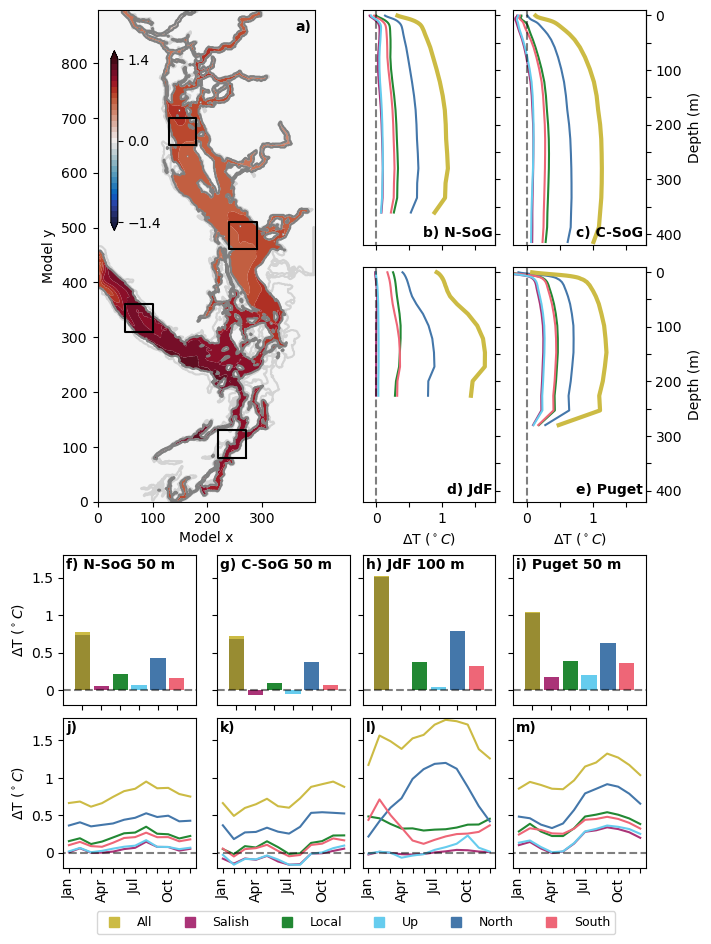

In [10]:
tracer = 'votemper'
name = 'temp'

fig = plt.figure(constrained_layout=True, figsize=[7,9])
gs = GridSpec(30,8, figure=fig)
map = fig.add_subplot(gs[:18, :4])
dep1 = fig.add_subplot(gs[:9, 4:6])
dep2 = fig.add_subplot(gs[:9, 6:])
dep3 = fig.add_subplot(gs[9:18, 4:6])
dep4 = fig.add_subplot(gs[9:18, 6:])
tot1 = fig.add_subplot(gs[18:24,:2])
tot2 = fig.add_subplot(gs[18:24,2:4])
tot3 = fig.add_subplot(gs[18:24,4:6])
tot4 = fig.add_subplot(gs[18:24,6:])
mon1 = fig.add_subplot(gs[24:,:2])
mon2 = fig.add_subplot(gs[24:,2:4])
mon3 = fig.add_subplot(gs[24:,4:6])
mon4 = fig.add_subplot(gs[24:,6:])

# insert text
map.text(0.98,0.98,'a)',ha='right',va='top',color='k',weight='semibold',transform=map.transAxes,fontsize=10,zorder=6)
dep1.text(0.98,0.02,'b) N-SoG',ha='right',va='bottom',color='k',weight='semibold',transform=dep1.transAxes,fontsize=10,zorder=6)
dep2.text(0.98,0.02,'c) C-SoG',ha='right',va='bottom',color='k',weight='semibold',transform=dep2.transAxes,fontsize=10,zorder=6)
dep3.text(0.98,0.02,'d) JdF',ha='right',va='bottom',color='k',weight='semibold',transform=dep3.transAxes,fontsize=10,zorder=6)
dep4.text(0.98,0.02,'e) Puget',ha='right',va='bottom',color='k',weight='semibold',transform=dep4.transAxes,fontsize=10,zorder=6)
tot1.text(0.02,0.98,'f) N-SoG 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot1.transAxes,fontsize=10,zorder=6)
tot2.text(0.02,0.98,'g) C-SoG 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot2.transAxes,fontsize=10,zorder=6)
tot3.text(0.02,0.98,'h) JdF 100 m',ha='left',va='top',color='k',weight='semibold',transform=tot3.transAxes,fontsize=10,zorder=6)
tot4.text(0.02,0.98,'i) Puget 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot4.transAxes,fontsize=10,zorder=6)
mon1.text(0.02,0.98,'j)',ha='left',va='top',color='k',weight='semibold',transform=mon1.transAxes,fontsize=10,zorder=6)
mon2.text(0.02,0.98,'k)',ha='left',va='top',color='k',weight='semibold',transform=mon2.transAxes,fontsize=10,zorder=6)
mon3.text(0.02,0.98,'l)',ha='left',va='top',color='k',weight='semibold',transform=mon3.transAxes,fontsize=10,zorder=6)
mon4.text(0.02,0.98,'m)',ha='left',va='top',color='k',weight='semibold',transform=mon4.transAxes,fontsize=10,zorder=6)

# insert legend
legend_handles = []
for i in range(len(scenarios)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker='s', linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],
                          label=scenarios[i]))
# Add a figure-wide legend below the subplots
fig.legend(handles=legend_handles, loc='upper center', ncol=7, bbox_to_anchor=(0.5, 0.001), frameon=True,fontsize=9)

#-----------------------------------------------------------------------------------------------
### MAP ###
###########
changemap(name,np.mean(all[tracer][:,0,...],axis=0),np.mean(base[tracer][:,0,...],axis=0),map)

#-----------------------------------------------------------------------------------------------
### DEPTH PROFILES ###
######################
profile(tracer,dep1,dep2,dep3,dep4)
# for ax in [dep1,dep3]:
#     ax.set_ylabel('Depth (m)')
#     ax.set_yticklabels(['0','','100','','200','','300','','400'],rotation=90)
for ax in [dep1,dep2,dep3,dep4]:
    ax.set_xlim([-0.2,1.8])
    ax.set_xticks([0,0.5,1,1.5])
    ax.set_xticklabels([])
for ax in [dep3,dep4]:
    ax.set_xticklabels(['0','','1',''])
    ax.set_xlabel(name_dict[name])

#-----------------------------------------------------------------------------------------------
### MEAN TOTAL CHANGE ###
#########################
meantotal(tracer,tot1,tot2,tot3,tot4)
for ax in [tot1,tot2,tot3,tot4]:
    ax.set_ylim([-0.2,1.8])
    ax.set_yticks([0,0.5,1,1.5])
    ax.set_yticklabels([])
tot1.set_yticklabels([0,0.5,1,1.5])
tot1.set_ylabel(name_dict[name])

#-----------------------------------------------------------------------------------------------
### MEAN MONTHLY CHANGE ###
###########################
monthly(tracer,mon1,mon2,mon3,mon4)
for ax in [mon1,mon2,mon3,mon4]:
    ax.set_ylim([-0.2,1.8])
    ax.set_yticks([0,0.5,1,1.5])
    ax.set_yticklabels([])
mon1.set_yticklabels([0,0.5,1,1.5])
mon1.set_ylabel(name_dict[name]) 


Text(0, 0.5, '$\\Delta$S$_A$ (g kg$^{-1}$)')

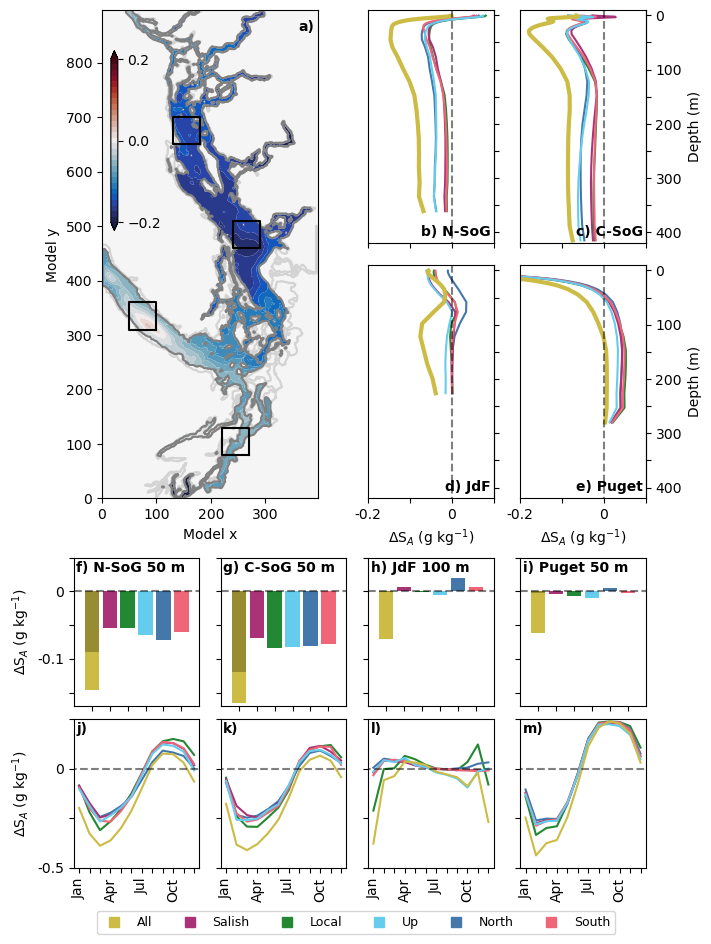

In [23]:
tracer = 'vosaline'
name = 'salt'

fig = plt.figure(constrained_layout=True, figsize=[7,9])
gs = GridSpec(30,8, figure=fig)
map = fig.add_subplot(gs[:18, :4])
dep1 = fig.add_subplot(gs[:9, 4:6])
dep2 = fig.add_subplot(gs[:9, 6:])
dep3 = fig.add_subplot(gs[9:18, 4:6])
dep4 = fig.add_subplot(gs[9:18, 6:])
tot1 = fig.add_subplot(gs[18:24,:2])
tot2 = fig.add_subplot(gs[18:24,2:4])
tot3 = fig.add_subplot(gs[18:24,4:6])
tot4 = fig.add_subplot(gs[18:24,6:])
mon1 = fig.add_subplot(gs[24:,:2])
mon2 = fig.add_subplot(gs[24:,2:4])
mon3 = fig.add_subplot(gs[24:,4:6])
mon4 = fig.add_subplot(gs[24:,6:])

# insert text
map.text(0.98,0.98,'a)',ha='right',va='top',color='k',weight='semibold',transform=map.transAxes,fontsize=10,zorder=6)
dep1.text(0.98,0.02,'b) N-SoG',ha='right',va='bottom',color='k',weight='semibold',transform=dep1.transAxes,fontsize=10,zorder=6)
dep2.text(0.98,0.02,'c) C-SoG',ha='right',va='bottom',color='k',weight='semibold',transform=dep2.transAxes,fontsize=10,zorder=6)
dep3.text(0.98,0.02,'d) JdF',ha='right',va='bottom',color='k',weight='semibold',transform=dep3.transAxes,fontsize=10,zorder=6)
dep4.text(0.98,0.02,'e) Puget',ha='right',va='bottom',color='k',weight='semibold',transform=dep4.transAxes,fontsize=10,zorder=6)
tot1.text(0.02,0.98,'f) N-SoG 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot1.transAxes,fontsize=10,zorder=6)
tot2.text(0.02,0.98,'g) C-SoG 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot2.transAxes,fontsize=10,zorder=6)
tot3.text(0.02,0.98,'h) JdF 100 m',ha='left',va='top',color='k',weight='semibold',transform=tot3.transAxes,fontsize=10,zorder=6)
tot4.text(0.02,0.98,'i) Puget 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot4.transAxes,fontsize=10,zorder=6)
mon1.text(0.02,0.98,'j)',ha='left',va='top',color='k',weight='semibold',transform=mon1.transAxes,fontsize=10,zorder=6)
mon2.text(0.02,0.98,'k)',ha='left',va='top',color='k',weight='semibold',transform=mon2.transAxes,fontsize=10,zorder=6)
mon3.text(0.02,0.98,'l)',ha='left',va='top',color='k',weight='semibold',transform=mon3.transAxes,fontsize=10,zorder=6)
mon4.text(0.02,0.98,'m)',ha='left',va='top',color='k',weight='semibold',transform=mon4.transAxes,fontsize=10,zorder=6)

# insert legend
legend_handles = []
for i in range(len(scenarios)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker='s', linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],
                          label=scenarios[i]))
# Add a figure-wide legend below the subplots
fig.legend(handles=legend_handles, loc='upper center', ncol=7, bbox_to_anchor=(0.5, 0.001), frameon=True,fontsize=9)

#-----------------------------------------------------------------------------------------------
### MAP ###
###########
changemap(name,np.mean(all[tracer][:,0,...],axis=0),np.mean(base[tracer][:,0,...],axis=0),map)


#-----------------------------------------------------------------------------------------------
### DEPTH PROFILES ###
######################
profile(tracer,dep1,dep2,dep3,dep4)
# for ax in [dep1,dep3]:
#     ax.set_ylabel('Depth (m)')
#     ax.set_yticklabels(['0','','100','','200','','300','','400'],rotation=90)
for ax in [dep1,dep2,dep3,dep4]:
    ax.set_xlim([-0.2,0.1])
    ax.set_xticks(np.arange(-0.2,0.11,0.1))
    ax.set_xticklabels([])
for ax in [dep3,dep4]:
    ax.set_xticklabels(['-0.2','','0',''])
    ax.set_xlabel(name_dict[name])

#-----------------------------------------------------------------------------------------------
### MEAN TOTAL CHANGE ###
#########################
meantotal(tracer,tot1,tot2,tot3,tot4)
for ax in [tot1,tot2,tot3,tot4]:
    ax.set_ylim([-0.17,0.05])
    ax.set_yticks(np.arange(-0.15,0.06,0.05))
    ax.set_yticklabels([])
tot1.set_yticklabels(['','-0.1','','0',''])
tot1.set_ylabel(name_dict[name])

#-----------------------------------------------------------------------------------------------
### MEAN MONTHLY CHANGE ###
###########################
monthly(tracer,mon1,mon2,mon3,mon4)
for ax in [mon1,mon2,mon3,mon4]:
    ax.set_ylim([-0.5,0.25])
    ax.set_yticks(np.arange(-0.5,0.26,0.25))
    ax.set_yticklabels([])
mon1.set_yticklabels(['-0.5','','0',''])
mon1.set_ylabel(name_dict[name]) 


Text(0, 0.5, '$\\Delta$DO ($\\mu mol \\, kg^{-1}$)')

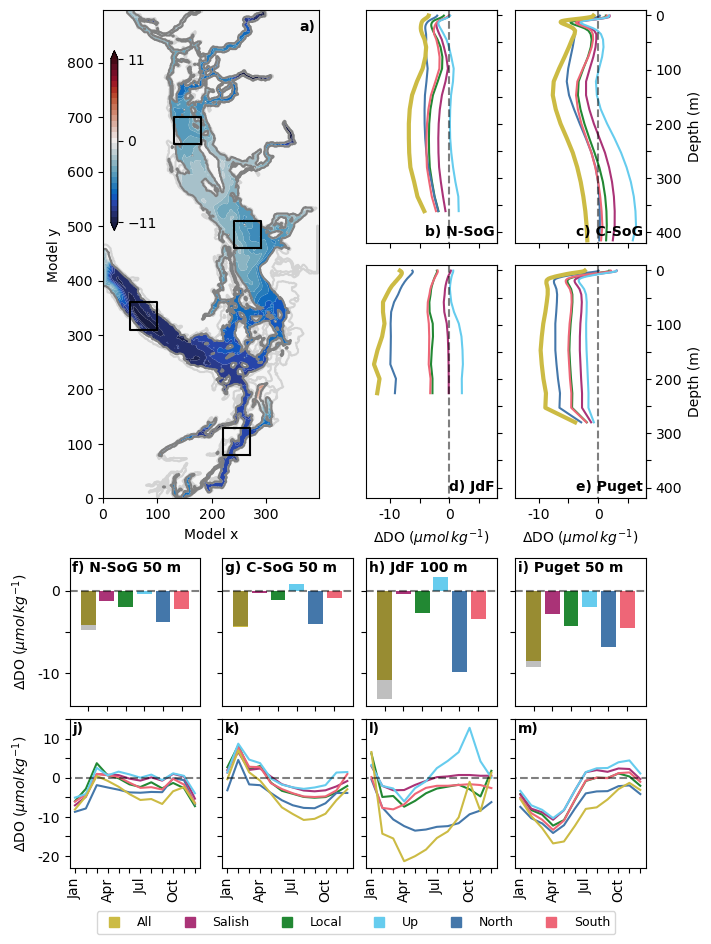

In [22]:
tracer = 'dissolved_oxygen'
name = 'do'

fig = plt.figure(constrained_layout=True, figsize=[7,9])
gs = GridSpec(30,8, figure=fig)
map = fig.add_subplot(gs[:18, :4])
dep1 = fig.add_subplot(gs[:9, 4:6])
dep2 = fig.add_subplot(gs[:9, 6:])
dep3 = fig.add_subplot(gs[9:18, 4:6])
dep4 = fig.add_subplot(gs[9:18, 6:])
tot1 = fig.add_subplot(gs[18:24,:2])
tot2 = fig.add_subplot(gs[18:24,2:4])
tot3 = fig.add_subplot(gs[18:24,4:6])
tot4 = fig.add_subplot(gs[18:24,6:])
mon1 = fig.add_subplot(gs[24:,:2])
mon2 = fig.add_subplot(gs[24:,2:4])
mon3 = fig.add_subplot(gs[24:,4:6])
mon4 = fig.add_subplot(gs[24:,6:])

# insert text
map.text(0.98,0.98,'a)',ha='right',va='top',color='k',weight='semibold',transform=map.transAxes,fontsize=10,zorder=6)
dep1.text(0.98,0.02,'b) N-SoG',ha='right',va='bottom',color='k',weight='semibold',transform=dep1.transAxes,fontsize=10,zorder=6)
dep2.text(0.98,0.02,'c) C-SoG',ha='right',va='bottom',color='k',weight='semibold',transform=dep2.transAxes,fontsize=10,zorder=6)
dep3.text(0.98,0.02,'d) JdF',ha='right',va='bottom',color='k',weight='semibold',transform=dep3.transAxes,fontsize=10,zorder=6)
dep4.text(0.98,0.02,'e) Puget',ha='right',va='bottom',color='k',weight='semibold',transform=dep4.transAxes,fontsize=10,zorder=6)
tot1.text(0.02,0.98,'f) N-SoG 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot1.transAxes,fontsize=10,zorder=6)
tot2.text(0.02,0.98,'g) C-SoG 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot2.transAxes,fontsize=10,zorder=6)
tot3.text(0.02,0.98,'h) JdF 100 m',ha='left',va='top',color='k',weight='semibold',transform=tot3.transAxes,fontsize=10,zorder=6)
tot4.text(0.02,0.98,'i) Puget 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot4.transAxes,fontsize=10,zorder=6)
mon1.text(0.02,0.98,'j)',ha='left',va='top',color='k',weight='semibold',transform=mon1.transAxes,fontsize=10,zorder=6)
mon2.text(0.02,0.98,'k)',ha='left',va='top',color='k',weight='semibold',transform=mon2.transAxes,fontsize=10,zorder=6)
mon3.text(0.02,0.98,'l)',ha='left',va='top',color='k',weight='semibold',transform=mon3.transAxes,fontsize=10,zorder=6)
mon4.text(0.02,0.98,'m)',ha='left',va='top',color='k',weight='semibold',transform=mon4.transAxes,fontsize=10,zorder=6)

# insert legend
legend_handles = []
for i in range(len(scenarios)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker='s', linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],
                          label=scenarios[i]))
# Add a figure-wide legend below the subplots
fig.legend(handles=legend_handles, loc='upper center', ncol=7, bbox_to_anchor=(0.5, 0.001), frameon=True,fontsize=9)

#-----------------------------------------------------------------------------------------------
### MAP ###
###########
changemap(name,np.mean(all[tracer][:,0,...],axis=0),np.mean(base[tracer][:,0,...],axis=0),map)


#-----------------------------------------------------------------------------------------------
### DEPTH PROFILES ###
######################
profile(tracer,dep1,dep2,dep3,dep4)
# for ax in [dep1,dep3]:
#     ax.set_ylabel('Depth (m)')
#     ax.set_yticklabels(['0','','100','','200','','300','','400'],rotation=90)
for ax in [dep1,dep2,dep3,dep4]:
    ax.set_xlim([-14,8])
    ax.set_xticks(np.arange(-10,6,5))
    ax.set_xticklabels([])
for ax in [dep3,dep4]:
    ax.set_xticklabels(['-10','','0',''])
    ax.set_xlabel(name_dict[name])

#-----------------------------------------------------------------------------------------------
### MEAN TOTAL CHANGE ###
#########################
meantotal(tracer,tot1,tot2,tot3,tot4)
for ax in [tot1,tot2,tot3,tot4]:
    ax.set_ylim([-14,4])
    ax.set_yticks(np.arange(-10,2,5))
    ax.set_yticklabels([])
tot1.set_yticklabels(['-10','','0'])
tot1.set_ylabel(name_dict[name])

#-----------------------------------------------------------------------------------------------
### MEAN MONTHLY CHANGE ###
###########################
monthly(tracer,mon1,mon2,mon3,mon4)
for ax in [mon1,mon2,mon3,mon4]:
    ax.set_ylim([-23,15])
    ax.set_yticks(np.arange(-20,16,5))
    ax.set_yticklabels([])
mon1.set_yticklabels(['-20','','-10','','0','','10',''])
mon1.set_ylabel(name_dict[name]) 


Text(0, 0.5, '$\\Delta$DIC ($\\mu mol \\, m^{-3}$)')

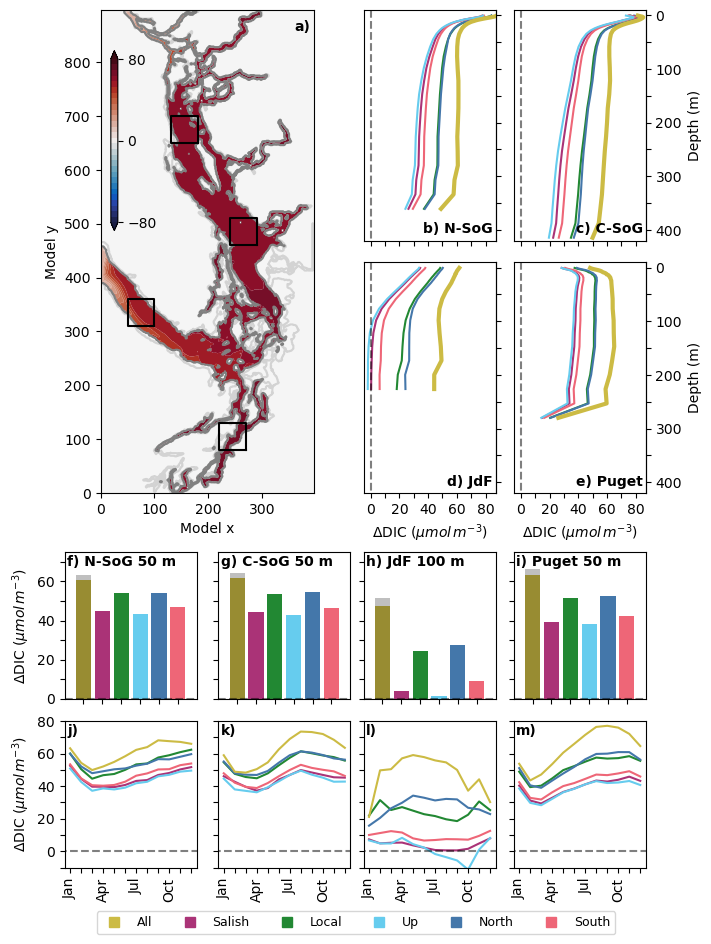

In [13]:
tracer = 'dissolved_inorganic_carbon'
name = 'dic'

fig = plt.figure(constrained_layout=True, figsize=[7,9])
gs = GridSpec(30,8, figure=fig)
map = fig.add_subplot(gs[:18, :4])
dep1 = fig.add_subplot(gs[:9, 4:6])
dep2 = fig.add_subplot(gs[:9, 6:])
dep3 = fig.add_subplot(gs[9:18, 4:6])
dep4 = fig.add_subplot(gs[9:18, 6:])
tot1 = fig.add_subplot(gs[18:24,:2])
tot2 = fig.add_subplot(gs[18:24,2:4])
tot3 = fig.add_subplot(gs[18:24,4:6])
tot4 = fig.add_subplot(gs[18:24,6:])
mon1 = fig.add_subplot(gs[24:,:2])
mon2 = fig.add_subplot(gs[24:,2:4])
mon3 = fig.add_subplot(gs[24:,4:6])
mon4 = fig.add_subplot(gs[24:,6:])

# insert text
map.text(0.98,0.98,'a)',ha='right',va='top',color='k',weight='semibold',transform=map.transAxes,fontsize=10,zorder=6)
dep1.text(0.98,0.02,'b) N-SoG',ha='right',va='bottom',color='k',weight='semibold',transform=dep1.transAxes,fontsize=10,zorder=6)
dep2.text(0.98,0.02,'c) C-SoG',ha='right',va='bottom',color='k',weight='semibold',transform=dep2.transAxes,fontsize=10,zorder=6)
dep3.text(0.98,0.02,'d) JdF',ha='right',va='bottom',color='k',weight='semibold',transform=dep3.transAxes,fontsize=10,zorder=6)
dep4.text(0.98,0.02,'e) Puget',ha='right',va='bottom',color='k',weight='semibold',transform=dep4.transAxes,fontsize=10,zorder=6)
tot1.text(0.02,0.98,'f) N-SoG 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot1.transAxes,fontsize=10,zorder=6)
tot2.text(0.02,0.98,'g) C-SoG 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot2.transAxes,fontsize=10,zorder=6)
tot3.text(0.02,0.98,'h) JdF 100 m',ha='left',va='top',color='k',weight='semibold',transform=tot3.transAxes,fontsize=10,zorder=6)
tot4.text(0.02,0.98,'i) Puget 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot4.transAxes,fontsize=10,zorder=6)
mon1.text(0.02,0.98,'j)',ha='left',va='top',color='k',weight='semibold',transform=mon1.transAxes,fontsize=10,zorder=6)
mon2.text(0.02,0.98,'k)',ha='left',va='top',color='k',weight='semibold',transform=mon2.transAxes,fontsize=10,zorder=6)
mon3.text(0.02,0.98,'l)',ha='left',va='top',color='k',weight='semibold',transform=mon3.transAxes,fontsize=10,zorder=6)
mon4.text(0.02,0.98,'m)',ha='left',va='top',color='k',weight='semibold',transform=mon4.transAxes,fontsize=10,zorder=6)

# insert legend
legend_handles = []
for i in range(len(scenarios)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker='s', linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],
                          label=scenarios[i]))
# Add a figure-wide legend below the subplots
fig.legend(handles=legend_handles, loc='upper center', ncol=7, bbox_to_anchor=(0.5, 0.001), frameon=True,fontsize=9)

#-----------------------------------------------------------------------------------------------
### MAP ###
###########
changemap(name,np.mean(all[tracer][:,0,...],axis=0),np.mean(base[tracer][:,0,...],axis=0),map)


#-----------------------------------------------------------------------------------------------
### DEPTH PROFILES ###
######################
profile(tracer,dep1,dep2,dep3,dep4)
# for ax in [dep1,dep3]:
#     ax.set_ylabel('Depth (m)')
#     ax.set_yticklabels(['0','','100','','200','','300','','400'],rotation=90)
for ax in [dep1,dep2,dep3,dep4]:
    ax.set_xlim([-5,87])
    ax.set_xticks(np.arange(0,81,10))
    ax.set_xticklabels([])
for ax in [dep3,dep4]:
    ax.set_xticklabels(['0','','20','','40','','60','','80'])
    ax.set_xlabel(name_dict[name])

#-----------------------------------------------------------------------------------------------
### MEAN TOTAL CHANGE ###
#########################
meantotal(tracer,tot1,tot2,tot3,tot4)
for ax in [tot1,tot2,tot3,tot4]:
    ax.set_ylim([0,75])
    ax.set_yticks(np.arange(0,71,10))
    ax.set_yticklabels([])
tot1.set_yticklabels(['0','','20','','40','','60',''])
tot1.set_ylabel(name_dict[name])

#-----------------------------------------------------------------------------------------------
### MEAN MONTHLY CHANGE ###
###########################
monthly(tracer,mon1,mon2,mon3,mon4)
for ax in [mon1,mon2,mon3,mon4]:
    ax.set_ylim([-10,80])
    ax.set_yticks(np.arange(-10,81,10))
    ax.set_yticklabels([])
mon1.set_yticklabels(['','0','','20','','40','','60','','80'])
mon1.set_ylabel(name_dict[name]) 


Text(0, 0.5, '$\\Delta$TA ($\\mu mol \\, m^{-3}$)')

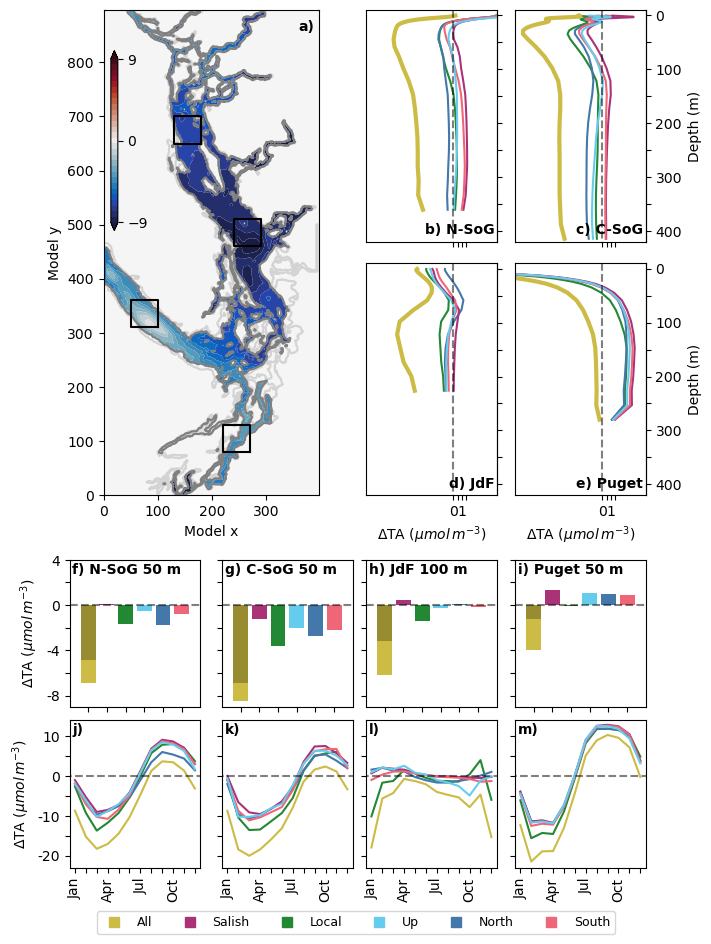

In [14]:
tracer = 'total_alkalinity'
name = 'ta'

fig = plt.figure(constrained_layout=True, figsize=[7,9])
gs = GridSpec(30,8, figure=fig)
map = fig.add_subplot(gs[:18, :4])
dep1 = fig.add_subplot(gs[:9, 4:6])
dep2 = fig.add_subplot(gs[:9, 6:])
dep3 = fig.add_subplot(gs[9:18, 4:6])
dep4 = fig.add_subplot(gs[9:18, 6:])
tot1 = fig.add_subplot(gs[18:24,:2])
tot2 = fig.add_subplot(gs[18:24,2:4])
tot3 = fig.add_subplot(gs[18:24,4:6])
tot4 = fig.add_subplot(gs[18:24,6:])
mon1 = fig.add_subplot(gs[24:,:2])
mon2 = fig.add_subplot(gs[24:,2:4])
mon3 = fig.add_subplot(gs[24:,4:6])
mon4 = fig.add_subplot(gs[24:,6:])

# insert text
map.text(0.98,0.98,'a)',ha='right',va='top',color='k',weight='semibold',transform=map.transAxes,fontsize=10,zorder=6)
dep1.text(0.98,0.02,'b) N-SoG',ha='right',va='bottom',color='k',weight='semibold',transform=dep1.transAxes,fontsize=10,zorder=6)
dep2.text(0.98,0.02,'c) C-SoG',ha='right',va='bottom',color='k',weight='semibold',transform=dep2.transAxes,fontsize=10,zorder=6)
dep3.text(0.98,0.02,'d) JdF',ha='right',va='bottom',color='k',weight='semibold',transform=dep3.transAxes,fontsize=10,zorder=6)
dep4.text(0.98,0.02,'e) Puget',ha='right',va='bottom',color='k',weight='semibold',transform=dep4.transAxes,fontsize=10,zorder=6)
tot1.text(0.02,0.98,'f) N-SoG 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot1.transAxes,fontsize=10,zorder=6)
tot2.text(0.02,0.98,'g) C-SoG 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot2.transAxes,fontsize=10,zorder=6)
tot3.text(0.02,0.98,'h) JdF 100 m',ha='left',va='top',color='k',weight='semibold',transform=tot3.transAxes,fontsize=10,zorder=6)
tot4.text(0.02,0.98,'i) Puget 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot4.transAxes,fontsize=10,zorder=6)
mon1.text(0.02,0.98,'j)',ha='left',va='top',color='k',weight='semibold',transform=mon1.transAxes,fontsize=10,zorder=6)
mon2.text(0.02,0.98,'k)',ha='left',va='top',color='k',weight='semibold',transform=mon2.transAxes,fontsize=10,zorder=6)
mon3.text(0.02,0.98,'l)',ha='left',va='top',color='k',weight='semibold',transform=mon3.transAxes,fontsize=10,zorder=6)
mon4.text(0.02,0.98,'m)',ha='left',va='top',color='k',weight='semibold',transform=mon4.transAxes,fontsize=10,zorder=6)

# insert legend
legend_handles = []
for i in range(len(scenarios)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker='s', linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],
                          label=scenarios[i]))
# Add a figure-wide legend below the subplots
fig.legend(handles=legend_handles, loc='upper center', ncol=7, bbox_to_anchor=(0.5, 0.001), frameon=True,fontsize=9)

#-----------------------------------------------------------------------------------------------
### MAP ###
###########
changemap(name,np.mean(all[tracer][:,0,...],axis=0),np.mean(base[tracer][:,0,...],axis=0),map)


#-----------------------------------------------------------------------------------------------
### DEPTH PROFILES ###
######################
profile(tracer,dep1,dep2,dep3,dep4)
for ax in [dep1,dep2,dep3,dep4]:
    ax.set_xlim([-10,5])
    ax.set_xticks([0,0.5,1,1.5])
    ax.set_xticklabels([])
for ax in [dep3,dep4]:
    ax.set_xticklabels(['0','','1',''])
    ax.set_xlabel(name_dict[name])

#-----------------------------------------------------------------------------------------------
### MEAN TOTAL CHANGE ###
#########################
meantotal(tracer,tot1,tot2,tot3,tot4)
for ax in [tot1,tot2,tot3,tot4]:
    ax.set_ylim([-9,4])
    ax.set_yticks(np.arange(-8,5,2))
    ax.set_yticklabels([])
tot1.set_yticklabels(['-8','','-4','','0','','4'])
tot1.set_ylabel(name_dict[name])

#-----------------------------------------------------------------------------------------------
### MEAN MONTHLY CHANGE ###
###########################
monthly(tracer,mon1,mon2,mon3,mon4)
for ax in [mon1,mon2,mon3,mon4]:
    ax.set_ylim([-23,14])
    ax.set_yticks(np.arange(-20,14,5))
    ax.set_yticklabels([])
mon1.set_yticklabels(['-20','','-10','','0','','10'])
mon1.set_ylabel(name_dict[name]) 


Text(0, 0.5, '$\\Delta$NO$_3$ ($\\mu mol \\, m^{-3}$)')

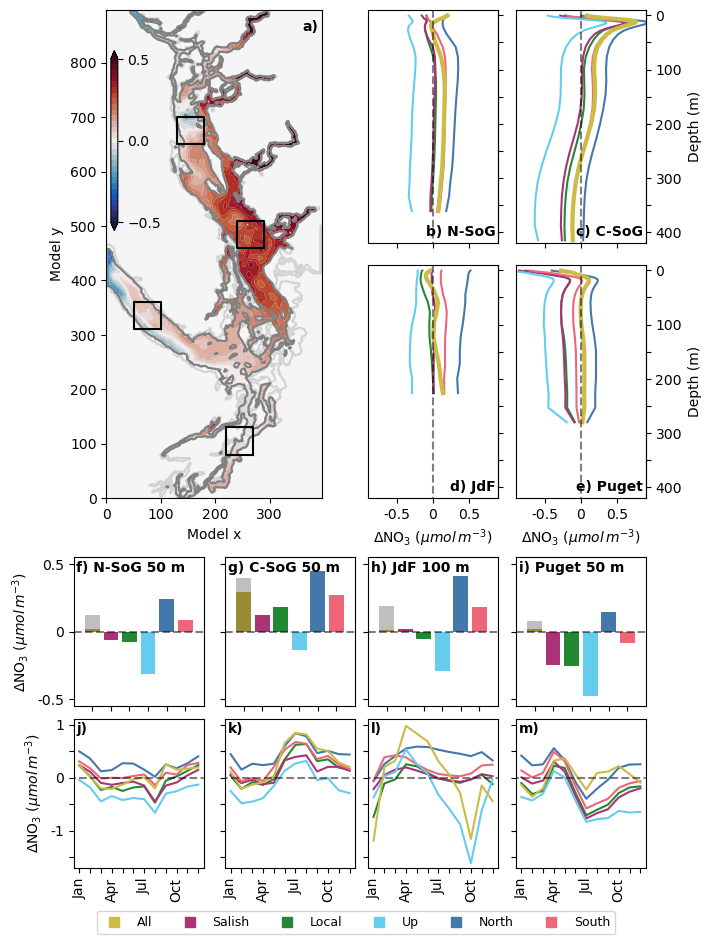

In [15]:
tracer = 'nitrate'
name = 'no3'

fig = plt.figure(constrained_layout=True, figsize=[7,9])
gs = GridSpec(30,8, figure=fig)
map = fig.add_subplot(gs[:18, :4])
dep1 = fig.add_subplot(gs[:9, 4:6])
dep2 = fig.add_subplot(gs[:9, 6:])
dep3 = fig.add_subplot(gs[9:18, 4:6])
dep4 = fig.add_subplot(gs[9:18, 6:])
tot1 = fig.add_subplot(gs[18:24,:2])
tot2 = fig.add_subplot(gs[18:24,2:4])
tot3 = fig.add_subplot(gs[18:24,4:6])
tot4 = fig.add_subplot(gs[18:24,6:])
mon1 = fig.add_subplot(gs[24:,:2])
mon2 = fig.add_subplot(gs[24:,2:4])
mon3 = fig.add_subplot(gs[24:,4:6])
mon4 = fig.add_subplot(gs[24:,6:])

# insert text
map.text(0.98,0.98,'a)',ha='right',va='top',color='k',weight='semibold',transform=map.transAxes,fontsize=10,zorder=6)
dep1.text(0.98,0.02,'b) N-SoG',ha='right',va='bottom',color='k',weight='semibold',transform=dep1.transAxes,fontsize=10,zorder=6)
dep2.text(0.98,0.02,'c) C-SoG',ha='right',va='bottom',color='k',weight='semibold',transform=dep2.transAxes,fontsize=10,zorder=6)
dep3.text(0.98,0.02,'d) JdF',ha='right',va='bottom',color='k',weight='semibold',transform=dep3.transAxes,fontsize=10,zorder=6)
dep4.text(0.98,0.02,'e) Puget',ha='right',va='bottom',color='k',weight='semibold',transform=dep4.transAxes,fontsize=10,zorder=6)
tot1.text(0.02,0.98,'f) N-SoG 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot1.transAxes,fontsize=10,zorder=6)
tot2.text(0.02,0.98,'g) C-SoG 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot2.transAxes,fontsize=10,zorder=6)
tot3.text(0.02,0.98,'h) JdF 100 m',ha='left',va='top',color='k',weight='semibold',transform=tot3.transAxes,fontsize=10,zorder=6)
tot4.text(0.02,0.98,'i) Puget 50 m',ha='left',va='top',color='k',weight='semibold',transform=tot4.transAxes,fontsize=10,zorder=6)
mon1.text(0.02,0.98,'j)',ha='left',va='top',color='k',weight='semibold',transform=mon1.transAxes,fontsize=10,zorder=6)
mon2.text(0.02,0.98,'k)',ha='left',va='top',color='k',weight='semibold',transform=mon2.transAxes,fontsize=10,zorder=6)
mon3.text(0.02,0.98,'l)',ha='left',va='top',color='k',weight='semibold',transform=mon3.transAxes,fontsize=10,zorder=6)
mon4.text(0.02,0.98,'m)',ha='left',va='top',color='k',weight='semibold',transform=mon4.transAxes,fontsize=10,zorder=6)

# insert legend
legend_handles = []
for i in range(len(scenarios)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker='s', linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],
                          label=scenarios[i]))
# Add a figure-wide legend below the subplots
fig.legend(handles=legend_handles, loc='upper center', ncol=7, bbox_to_anchor=(0.5, 0.001), frameon=True,fontsize=9)

#-----------------------------------------------------------------------------------------------
### MAP ###
###########
changemap(name,np.mean(all[tracer][:,0,...],axis=0),np.mean(base[tracer][:,0,...],axis=0),map)


#-----------------------------------------------------------------------------------------------
### DEPTH PROFILES ###
######################
profile(tracer,dep1,dep2,dep3,dep4)
for ax in [dep1,dep2,dep3,dep4]:
    ax.set_xlim([-0.9,0.9])
    ax.set_xticks([-0.5,0,0.5])
    ax.set_xticklabels([])
for ax in [dep3,dep4]:
    ax.set_xticklabels([-0.5,0,0.5])
    ax.set_xlabel(name_dict[name])

#-----------------------------------------------------------------------------------------------
### MEAN TOTAL CHANGE ###
#########################
meantotal(tracer,tot1,tot2,tot3,tot4)
for ax in [tot1,tot2,tot3,tot4]:
    ax.set_ylim([-0.55,0.55])
    ax.set_yticks([-0.5,0,0.5])
    ax.set_yticklabels([])
tot1.set_yticklabels([-0.5,0,0.5])
tot1.set_ylabel(name_dict[name])

#-----------------------------------------------------------------------------------------------
### MEAN MONTHLY CHANGE ###
###########################
monthly(tracer,mon1,mon2,mon3,mon4)
for ax in [mon1,mon2,mon3,mon4]:
    ax.set_ylim([-1.7,1.1])
    ax.set_yticks([-1.5,-1,-0.5,0,0.5,1])
    ax.set_yticklabels([])
mon1.set_yticklabels(['','-1','','0','','1'])
mon1.set_ylabel(name_dict[name]) 
